In [1]:
# import modules
import numpy as np
import tensorflow as tf
from tensorflow import keras
import pandas as pd
import seaborn as sns
from pylab import rcParams
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupShuffleSplit
from scipy import stats
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import train_test_split
from tensorflow.keras import optimizers
from datetime import datetime
from kerastuner.tuners import RandomSearch
import tensorflow_addons as tfa
from keras.utils import to_categorical 
from keras.regularizers import l2
from scipy.stats import mode



r_seed = 42

WORKDIR = 'C:/Users/cristiano.nascimento/git/LSTM_giroscopio_acelerometro'
np.random.seed(r_seed)
tf.random.set_seed(r_seed)
data_hora= datetime.now().strftime('%Y-%m-%d_%H-%M-%S')
LOG_DIR = WORKDIR + "/Code/DataPrep/"+data_hora

C:\Users\cristiano.nascimento\AppData\Local\Temp\ipykernel_72260\2084090043.py:15: DeprecationWarning: `import kerastuner` is deprecated, please use `import keras_tuner`.
  from kerastuner.tuners import RandomSearch
c:\Users\cristiano.nascimento\git\LSTM_giroscopio_acelerometro\.venv\lib\site-packages\tensorflow_addons\utils\tfa_eol_msg.py:23: UserWarning: 

TensorFlow Addons (TFA) has ended development and introduction of new features.
TFA has entered a minimal maintenance and release mode until a planned end of life in May 2024.
Please modify downstream libraries to take dependencies from other repositories in our TensorFlow community (e.g. Keras, Keras-CV, and Keras-NLP). 

For more information see: https://github.com/tensorflow/addons/issues/2807 

  warnings.warn(


In [2]:
## get dataset
pd.set_option("display.precision", 9)

labels =['StandingUpFS',
'StandingUpFL',
'Walking',
'Running',
'GoingUpS',
'Jumping',
'GoingDonwS',
'LyingDonwFS',
'SittingDown']
# select only sensor data from smart watches



In [3]:
adl_data = np.load(WORKDIR+'/Data/UNIMIB-SHAR/adl_data.npy',allow_pickle=True)

In [4]:
adl_data = pd.DataFrame(adl_data)

In [5]:
adl_data.shape

(7579, 453)

In [6]:
adl_data.head()

,0,1,2,3,4,5,6,7,8,9,...,443,444,445,446,447,448,449,450,451,452
0,7.609005324,7.322881624,7.281458000,7.753252975,8.043098785,8.215854029,8.388744746,8.578034336,8.658355949,8.670647745,...,-6.372120389,-6.323450000,-6.474439938,-6.449741844,-6.415009860,-6.514917946,-6.590504364,-6.535513814,-6.453252069,-6.182646800
1,8.507709000,8.480922372,8.747757492,8.863954425,8.863968376,8.458412696,7.782317342,7.412025900,7.589060953,7.709208608,...,-6.785399713,-6.583993264,-6.291559573,-6.472509671,-6.626783193,-6.774499937,-6.929721671,-6.846733584,-6.704523541,-6.513263797
2,8.442040396,8.632097686,8.730012182,8.697697839,8.552649541,8.057507907,0.395887949,-0.090756437,-0.335575011,-0.507582163,...,-6.403487337,-6.450790528,-6.612762268,-6.830471904,-6.872513943,-7.249797590,-7.414934568,-7.278581209,-7.127101560,-6.832013909
3,-11.025565773,-11.714652456,-11.765208033,-9.944633699,-7.660169437,-6.882159548,-7.601299241,-9.161294094,-10.339049523,-11.046978405,...,-7.715562701,-7.764263449,-7.755619207,-8.040818876,-8.091954629,-7.817942600,-7.768973746,-7.687118196,-7.795513790,-7.819322735
4,0.238471558,0.321548855,0.383801880,0.495767001,0.664556218,0.776264244,1.019608510,1.010644705,0.850411656,0.473916180,...,-7.614920052,-7.553617527,-7.381001956,-7.324490962,-7.473059700,-7.441543048,-7.546224051,-7.474857599,-7.441729911,-7.412474949


In [7]:
adl_labels = np.load(WORKDIR+'/Data/UNIMIB-SHAR/adl_labels.npy')

In [8]:
adl_labels = pd.DataFrame(adl_labels)

In [9]:
adl_labels.head()

,0,1,2
0,1,1,1
1,1,1,1
2,1,1,1
3,1,1,2
4,1,1,2


In [10]:
adl_labels.tail()

,0,1,2
7574,9,29,2
7575,9,29,2
7576,9,30,2
7577,9,30,2
7578,9,30,2


In [11]:
adl_labels.shape

(7579, 3)

In [12]:
adl_labels[0].value_counts()

0
4    1985
3    1738
7    1324
5     921
6     746
8     296
2     216
9     200
1     153
Name: count, dtype: int64

In [13]:

# Sample DataFrames
# Assuming df_variables and df_labels are the variable and label DataFrames respectively
# df_variables = pd.DataFrame(...)  # Replace with your actual data
# df_labels = pd.DataFrame(...)  # Replace with your actual data

adl_labels_filtered = adl_labels[adl_labels.iloc[:, 0].isin([1,2,3,8,9])]
adl_data_filtered = adl_data.loc[adl_labels_filtered.index]

print(adl_labels_filtered.shape)
print(adl_data_filtered.shape)




(2603, 3)
(2603, 453)


In [14]:
# Step 1: Filter labels_train_data where the second column of labels is from 1 to 9

training_subjects = range(10,31)

labels_train = adl_labels_filtered[adl_labels_filtered.iloc[:, 1].isin(training_subjects)]
# Step 2: Create x_train_data according to index values of filtered labels_train_data
X_train_data= adl_data_filtered.loc[labels_train.index]

# Step 3: Create x_validation_data and labels_validation_data with the remaining data
X_validation_data = adl_data_filtered.drop(labels_train.index)
labels_val = adl_labels_filtered.drop(labels_train.index)

# Display the results
X_train_data.shape, labels_train.shape, X_validation_data.shape, labels_val.shape

((1901, 453), (1901, 3), (702, 453), (702, 3))

In [15]:
labels_train[0].value_counts().sort_index()

0
1     122
2     165
3    1260
8     208
9     146
Name: count, dtype: int64

In [16]:
labels_val[0].value_counts().sort_index()

0
1     31
2     51
3    478
8     88
9     54
Name: count, dtype: int64

# **Data Exploration**

In [17]:
# Define the mapping dictionary
mapping_dict = {1:0,2:1,3:2,8:3,9:4}


In [18]:
labels_train[0] = labels_train[0].replace(to_replace=mapping_dict)

C:\Users\cristiano.nascimento\AppData\Local\Temp\ipykernel_72260\1532996978.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  labels_train[0] = labels_train[0].replace(to_replace=mapping_dict)


In [19]:
labels_val[0] = labels_val[0].replace(to_replace=mapping_dict)

In [20]:
labels_train[0].value_counts().sort_index()

0
0     122
1     165
2    1260
3     208
4     146
Name: count, dtype: int64

In [21]:
labels_val[0].value_counts().sort_index()

0
0     31
1     51
2    478
3     88
4     54
Name: count, dtype: int64

In [22]:
X_train_data.shape

(1901, 453)

In [23]:
labels_train.shape

(1901, 3)

In [24]:
X_validation_data.shape


(702, 453)

In [25]:
labels_val.shape

(702, 3)

In [26]:
from imblearn.over_sampling import SMOTE
from collections import Counter
import pandas as pd

def balance_data_with_smote(_x_data, label_data):
    """
    Balances the class distribution in a DataFrame using SMOTE.

    Parameters:
        data (pd.DataFrame): The input DataFrame containing features and labels.
        label_column (str): The name of the column containing class labels.

    Returns:
        pd.DataFrame: A balanced DataFrame with the same structure as the input.
    """
    # Separate features and labels
    X = _x_data
    y = label_data

    # Check class distribution before SMOTE
    print("Before SMOTE:", Counter(y))

    # Apply SMOTE
    smote = SMOTE(sampling_strategy='auto', random_state=42)
    X_smote, y_smote = smote.fit_resample(X, y)

    # Check class distribution after SMOTE
    print("After SMOTE:", Counter(y_smote)) 
    print(X_smote.shape) 
    print(X_smote.shape) 

    return X_smote, y_smote

# Example usage:
# balanced_df = balance_data_with_smote(data, label_column='label')


In [27]:
X_train_data,labels_train = balance_data_with_smote(X_train_data,labels_train[0].values)

Before SMOTE: Counter({2: 1260, 3: 208, 1: 165, 4: 146, 0: 122})
After SMOTE: Counter({0: 1260, 1: 1260, 2: 1260, 3: 1260, 4: 1260})
(6300, 453)
(6300, 453)


In [28]:
print(X_train_data.shape)
print(labels_train.shape)

(6300, 453)
(6300,)


# **Models**

In [29]:
labels_val_categorical = to_categorical(labels_val[0],num_classes=5)

In [30]:
print(labels_val_categorical)

[[1. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0.]
 ...
 [0. 0. 0. 0. 1.]
 [0. 0. 0. 0. 1.]
 [0. 0. 0. 0. 1.]]


In [31]:
print(labels_val_categorical.shape)

(702, 5)


In [32]:
#print(occurrence_transitions_slide)

In [33]:
labels_train_categorical = to_categorical(labels_train,num_classes=5)

In [34]:
print(labels_train_categorical)

[[1. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0.]
 ...
 [0. 0. 0. 0. 1.]
 [0. 0. 0. 0. 1.]
 [0. 0. 0. 0. 1.]]


In [35]:
print(labels_train_categorical.shape)

(6300, 5)


In [36]:
X_train = X_train_data
y_train = labels_train_categorical
X_validation = X_validation_data
y_validation = labels_val_categorical

In [37]:
X_train = X_train.values

In [38]:
X_train = np.expand_dims(X_train, axis=-2) 

In [39]:
X_train.shape

(6300, 1, 453)

In [40]:
X_validation = X_validation.values

In [41]:
X_validation = np.expand_dims(X_validation, axis=-2) 

In [42]:
print(X_train.shape)
print(y_train.shape)
print(X_validation.shape)
print(y_validation.shape)

(6300, 1, 453)
(6300, 5)
(702, 1, 453)
(702, 5)


In [43]:
def shuffle_data(variable_data,label_data):
    perm_indices = np.random.permutation(variable_data.shape[0])
    # Shuffle both arrays using the same permutation indices
    shuffled_variable_data = variable_data[perm_indices]
    shuffled_label_data = label_data[perm_indices]
    return (shuffled_variable_data,shuffled_label_data)

In [44]:
#X_train,y_train = shuffle_data(X_train,y_train)
#X_validation,y_validation = shuffle_data(X_validation,y_validation)

In [45]:
print(X_train.shape)
print(y_train.shape)
print(X_validation.shape)
print(y_validation.shape)

(6300, 1, 453)
(6300, 5)
(702, 1, 453)
(702, 5)


In [ ]:
#from tensorflow.keras import regularizers

In [47]:
''' def cria_LSTM(hp):
  model = tf.keras.Sequential()  
  model.add(tf.keras.layers.LSTM(hp.Int("input_units",min_value=32,max_value=256,step=32), input_shape=(200,6), return_sequences=False))
  model.add(tf.keras.layers.Dense(hp.Int("input_units_relu",min_value=32,max_value=256,step=32), activation='relu'))
  model.add(tf.keras.layers.BatchNormalization())  
  model.add(tf.keras.layers.Dense(units=4, activation='softmax'))
  model.compile(loss='categorical_crossentropy', optimizer=tf.keras.optimizers.Adam(hp.Float(
                    'learning_rate',
                    min_value=1e-4,
                    max_value=1e-2,
                    sampling='LOG',
                    default=1e-3
                )), metrics=['accuracy'])
  return model
 '''

' def cria_LSTM(hp):\n  model = tf.keras.Sequential()  \n  model.add(tf.keras.layers.LSTM(hp.Int("input_units",min_value=32,max_value=256,step=32), input_shape=(200,6), return_sequences=False))\n  model.add(tf.keras.layers.Dense(hp.Int("input_units_relu",min_value=32,max_value=256,step=32), activation=\'relu\'))\n  model.add(tf.keras.layers.BatchNormalization())  \n  model.add(tf.keras.layers.Dense(units=4, activation=\'softmax\'))\n  model.compile(loss=\'categorical_crossentropy\', optimizer=tf.keras.optimizers.Adam(hp.Float(\n                    \'learning_rate\',\n                    min_value=1e-4,\n                    max_value=1e-2,\n                    sampling=\'LOG\',\n                    default=1e-3\n                )), metrics=[\'accuracy\'])\n  return model\n '

In [48]:
from keras.models import Model
from keras.layers import Input, LSTM, Dense, Dropout, Attention, BatchNormalization
from keras.regularizers import l2
import tensorflow as tf

def lstm_attention_sensor(hp):
    inputs = Input(shape=(1, 453))
    
    # LSTM layer with dropout and regularization
    lstm_out = LSTM(
        hp.Int("input_units_lstm1", min_value=32, max_value=128, step=32),
        kernel_regularizer=l2(hp.Float('l2_reg1', min_value=0.01, max_value=0.1, sampling='log')),
        recurrent_regularizer=l2(hp.Float('l2_reg1', min_value=0.01, max_value=0.1, sampling='log')),
        return_sequences=True
    )(inputs)
    lstm_out = Dropout(0.3)(lstm_out)
    lstm_out = BatchNormalization()(lstm_out)

    # Dense layer
    dense_out = Dense(hp.Int("input_units_lstm1", min_value=32, max_value=128, step=32), activation='relu')(lstm_out)
    dense_out = Dropout(0.3)(dense_out)
    dense_out = BatchNormalization()(dense_out)

    # Attention mechanism
    attention = Attention(use_scale=True)([dense_out, dense_out])
    context_vector = tf.reduce_sum(attention, axis=1)
    
    # Output layer
    output = Dense(5, activation='softmax')(context_vector)
    
    # Model definition
    model = Model(inputs=inputs, outputs=output)
    model.compile(
        loss='categorical_crossentropy', 
        optimizer=tf.keras.optimizers.Adam(hp.Float('learning_rate', min_value=1e-4, max_value=1e-2, sampling='LOG')),
        metrics=['accuracy']
    )
    
    return model


In [49]:
""" from keras.models import Model
from keras.layers import Input, LSTM, Dense, Dropout, Activation, Permute, Multiply, Lambda, Reshape
import keras.backend as K

def lstm_attention_sensor(hp):
    inputs = Input(shape=(200,6))
    lstm_out = LSTM(hp.Int("input_units_lstm1",min_value=32,max_value=256,step=32), kernel_regularizer=l2(hp.Float('l2_reg1', min_value=0.001, max_value=0.1, sampling='log')),
             recurrent_regularizer=l2(hp.Float('l2_reg1', min_value=0.001, max_value=0.1, sampling='log')),return_sequences=True)(inputs)
    
    # Attention mechanism
    attention = Dense(hp.Int("input_units_lstm1",min_value=32,max_value=256,step=32), activation='relu')(lstm_out)    
    attention = Permute([2, 1])(attention)
    attention = Activation('softmax')(attention)
    attention = Permute([2, 1])(attention)
    
    context_vector = Multiply()([lstm_out, attention])
    context_vector = Lambda(lambda x: K.sum(x, axis=1))(context_vector)    
    output = Dense(6, activation='softmax')(context_vector)
    
    model = Model(inputs=inputs, outputs=output)
    model.compile(loss='categorical_crossentropy', optimizer=tf.keras.optimizers.Adam(hp.Float(
                    'learning_rate',
                    min_value=1e-4,
                    max_value=1e-2,
                    sampling='LOG',
                    default=1e-3
                )), metrics=['accuracy'])
    return model
 """

' from keras.models import Model\nfrom keras.layers import Input, LSTM, Dense, Dropout, Activation, Permute, Multiply, Lambda, Reshape\nimport keras.backend as K\n\ndef lstm_attention_sensor(hp):\n    inputs = Input(shape=(200,6))\n    lstm_out = LSTM(hp.Int("input_units_lstm1",min_value=32,max_value=256,step=32), kernel_regularizer=l2(hp.Float(\'l2_reg1\', min_value=0.001, max_value=0.1, sampling=\'log\')),\n             recurrent_regularizer=l2(hp.Float(\'l2_reg1\', min_value=0.001, max_value=0.1, sampling=\'log\')),return_sequences=True)(inputs)\n    \n    # Attention mechanism\n    attention = Dense(hp.Int("input_units_lstm1",min_value=32,max_value=256,step=32), activation=\'relu\')(lstm_out)    \n    attention = Permute([2, 1])(attention)\n    attention = Activation(\'softmax\')(attention)\n    attention = Permute([2, 1])(attention)\n    \n    context_vector = Multiply()([lstm_out, attention])\n    context_vector = Lambda(lambda x: K.sum(x, axis=1))(context_vector)    \n    output

In [50]:
tuner = RandomSearch(
    lstm_attention_sensor,
    objective = 'val_accuracy', 
    seed=42,
    max_trials = 5,
    overwrite=True,        
    executions_per_trial = 1,    
    directory = LOG_DIR,
    project_name="lstm_acel_giro_multiclass")

In [51]:
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=5,
    min_delta = 0,
    verbose=1,
    restore_best_weights=True)

reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=3,
    verbose=1)

tensorboard = tf.keras.callbacks.TensorBoard(LOG_DIR)

my_callbacks = [early_stopping,reduce_lr,tensorboard]  


In [52]:
tuner.search(x=X_train,
            y=y_train,
            epochs=50,
            validation_data=(X_validation,y_validation), callbacks=my_callbacks,batch_size=8, use_multiprocessing=True)

Trial 5 Complete [00h 05m 06s]
val_accuracy: 0.8618233799934387

Best val_accuracy So Far: 0.8703703880310059
Total elapsed time: 00h 15m 16s


In [53]:
tuner.results_summary()

Results summary
Results in C:/Users/cristiano.nascimento/git/LSTM_giroscopio_acelerometro/Code/DataPrep/2024-11-20_13-04-55\lstm_acel_giro_multiclass
Showing 10 best trials
Objective(name="val_accuracy", direction="max")

Trial 1 summary
Hyperparameters:
input_units_lstm1: 64
l2_reg1: 0.07731576839806803
learning_rate: 0.000505466655750672
Score: 0.8703703880310059

Trial 2 summary
Hyperparameters:
input_units_lstm1: 96
l2_reg1: 0.01166497940438329
learning_rate: 0.0009887195863122636
Score: 0.8689458966255188

Trial 4 summary
Hyperparameters:
input_units_lstm1: 128
l2_reg1: 0.012312318862783698
learning_rate: 0.008547485565344062
Score: 0.8618233799934387

Trial 0 summary
Hyperparameters:
input_units_lstm1: 96
l2_reg1: 0.010928280642635886
learning_rate: 0.0006562536901904111
Score: 0.8518518805503845

Trial 3 summary
Hyperparameters:
input_units_lstm1: 32
l2_reg1: 0.09513818422602263
learning_rate: 0.001715074355925934
Score: 0.8490028381347656


In [54]:
tuner.get_best_hyperparameters()[0].values

{'input_units_lstm1': 64,
 'l2_reg1': 0.07731576839806803,
 'learning_rate': 0.000505466655750672}

In [55]:
best_model = tuner.get_best_models(num_models=1)[0]

In [56]:
best_model.history

In [57]:
best_model.summary()

Model: "model"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 input_1 (InputLayer)        [(None, 1, 453)]             0         []                            
                                                                                                  
 lstm (LSTM)                 (None, 1, 64)                132608    ['input_1[0][0]']             
                                                                                                  
 dropout (Dropout)           (None, 1, 64)                0         ['lstm[0][0]']                
                                                                                                  
 batch_normalization (Batch  (None, 1, 64)                256       ['dropout[0][0]']             
 Normalization)                                                                               

In [58]:
loss, accuracy = best_model.evaluate(X_validation, y_validation)

22/22 [==============================] - 1s 5ms/step - loss: 0.6845 - accuracy: 0.8704


In [59]:
predictions = best_model.predict(X_validation)

22/22 [==============================] - 1s 3ms/step


In [60]:
print(y_validation)

[[1. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0.]
 ...
 [0. 0. 0. 0. 1.]
 [0. 0. 0. 0. 1.]
 [0. 0. 0. 0. 1.]]


In [61]:
print(y_validation.shape)

(702, 5)


In [62]:
y_validation_inverse = np.argmax(y_validation, axis=1)

In [63]:
print(y_validation_inverse)

[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 

In [64]:
print(len(y_validation_inverse))

702


In [65]:
print(predictions)

[[9.5906228e-01 4.0101476e-02 7.0936199e-05 6.7603192e-04 8.9288944e-05]
 [9.4087172e-01 5.8795396e-02 3.9472096e-05 2.3826049e-04 5.5209279e-05]
 [7.8702813e-01 2.1214244e-01 2.4194233e-05 6.8853056e-04 1.1666582e-04]
 ...
 [1.5511546e-04 1.8722562e-03 3.0033703e-05 4.5213114e-02 9.5272952e-01]
 [1.9085349e-04 3.1456701e-03 5.5574594e-05 6.6100180e-02 9.3050772e-01]
 [4.2748856e-04 4.2759399e-03 4.4820437e-05 8.0629624e-02 9.1462213e-01]]


In [66]:
classes_x=np.argmax(predictions,axis=1)

In [67]:
print(classes_x)

[0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 1 1 1 0 0 1 1 0 0 3 3 3 0 1 1 1 1 1
 1 1 1 0 1 1 1 0 1 1 0 0 1 1 1 1 3 3 0 2 0 1 1 1 1 2 1 1 1 1 1 1 1 1 1 3 1
 1 1 1 1 4 3 3 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 3 3 3 3 3 3 3 3 3 3 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 

In [68]:
print(len(classes_x))

702


In [69]:
print(classes_x.shape)

(702,)


In [70]:
from sklearn.metrics import confusion_matrix,ConfusionMatrixDisplay,classification_report
cm = confusion_matrix(y_validation_inverse, classes_x)

In [71]:
disp = ConfusionMatrixDisplay(confusion_matrix=cm)

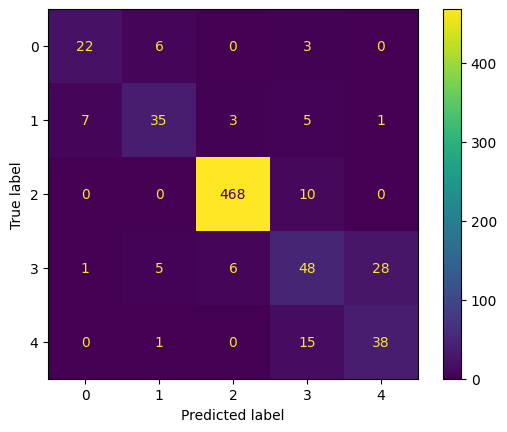

In [72]:
disp.plot()

In [73]:
print(classification_report(y_validation_inverse, classes_x))

              precision    recall  f1-score   support

           0       0.73      0.71      0.72        31
           1       0.74      0.69      0.71        51
           2       0.98      0.98      0.98       478
           3       0.59      0.55      0.57        88
           4       0.57      0.70      0.63        54

    accuracy                           0.87       702
   macro avg       0.72      0.72      0.72       702
weighted avg       0.87      0.87      0.87       702



In [ ]:
print(segments_test)

In [ ]:
print(labels_test_categorical.shape)

In [ ]:
print(labels_test_categorical)

In [ ]:
loss_test, accuracy_test = best_model.evaluate(segments_test, labels_test_categorical)

In [ ]:
predictions_test = best_model.predict(segments_test)

In [ ]:
print(predictions_test)

In [ ]:
classes_x_test=np.argmax(predictions_test,axis=1)

In [ ]:
print(classes_x_test)

In [ ]:
labels_test_argmax = np.argmax(labels_test_categorical,axis=1)

In [ ]:
print(labels_test_argmax)

In [ ]:
from sklearn.metrics import confusion_matrix,ConfusionMatrixDisplay,classification_report
cm_test = confusion_matrix(labels_test_argmax, classes_x_test)

In [ ]:
disp_test = ConfusionMatrixDisplay(confusion_matrix=cm_test)
disp_test.plot()

In [ ]:
print(classification_report(labels_test_argmax, classes_x_test))

In [ ]:
best_model.save(WORKDIR+"/Model/best_models_saved_"+data_hora)